# Rider Cancellation Risk Prediction
### From raw operational records to a reproducible cancellation-risk experiment

**Decision:** which newly allocated orders should an operations team review first?
**Prediction time:** immediately after the allocation recorded in `allot_time`.
**Target:** the supplied binary `cancelled` label. The dataset does not identify the
cancellation initiator or establish rider fault.

This notebook presents the completed experiment, reads its saved results, and
demonstrates the reusable scoring pipeline. The command-line package contains the
authoritative training implementation. Raw input files remain unchanged.

**Reading guide:** data audit → descriptive analysis → leakage controls → temporal
validation → models → measured results → interpretation → batch inference → limitations.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / "src" / "rider_cancellation").exists():
    ROOT = ROOT.parent
assert (ROOT / "src" / "rider_cancellation").exists(), "Open this notebook from the project directory."
sys.path.insert(0, str(ROOT / "src"))
from rider_cancellation.features import AllocationFeatures
from rider_cancellation.data import validate_training, chronological_split
from rider_cancellation.predict import predict_frame
import joblib
pd.set_option("display.max_columns", 24)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
print("Project:", ROOT.name)

Project: Rider_Cancellation


## 1. Understand the source data
The supplied files consist of labeled training orders, later unlabeled orders,
and a submission template. Timestamp timezone, distance units, aggregation windows,
dataset license, and collection provenance were not supplied. These are open questions,
not invented metadata.

In [2]:
train_raw = pd.read_csv(ROOT / "data/raw/train.csv")
test_raw = pd.read_csv(ROOT / "data/raw/test.csv")
template = pd.read_csv(ROOT / "data/raw/sample_submission.csv")
display(pd.DataFrame({"dataset": ["training", "test", "submission template"],
                      "rows": [len(train_raw), len(test_raw), len(template)],
                      "columns": [train_raw.shape[1], test_raw.shape[1], template.shape[1]]}))
display(train_raw.head(3))
display(pd.DataFrame({"dtype": train_raw.dtypes.astype(str),
                      "missing_fraction": train_raw.isna().mean(),
                      "unique_values": train_raw.nunique()}).sort_values("missing_fraction", ascending=False))

,dataset,rows,columns
0,training,450000,20
1,test,144844,16
2,submission template,144844,2


,order_time,order_id,order_date,allot_time,accept_time,pickup_time,delivered_time,rider_id,first_mile_distance,last_mile_distance,alloted_orders,delivered_orders,cancelled,undelivered_orders,lifetime_order_count,reassignment_method,reassignment_reason,reassigned_order,session_time,cancelled_time
0,2021-01-26 02:21:35,556753,2021-01-26 00:00:00,2021-01-26 02:21:59,2021-01-26 02:22:08,2021-01-26 02:32:51,2021-01-26 02:49:47,11696,1.5666,2.65,46.0,46.0,0,0.0,621.0,NaN,NaN,NaN,NaN,NaN
1,2021-01-26 02:33:16,556754,2021-01-26 00:00:00,2021-01-26 02:33:57,2021-01-26 02:34:45,2021-01-26 02:50:25,2021-01-26 03:11:15,18117,2.5207,2.76,8.0,8.0,0,0.0,105.0,NaN,NaN,NaN,3.266667,NaN
2,2021-01-26 02:39:49,556755,2021-01-26 00:00:00,2021-01-26 02:39:57,2021-01-26 02:40:13,2021-01-26 02:56:00,2021-01-26 03:12:46,18623,2.2074,4.80,1.0,1.0,0,0.0,66.0,NaN,NaN,NaN,9.816667,NaN


,dtype,missing_fraction,unique_values
cancelled_time,object,0.988404,5176
reassignment_method,object,0.969458,2
reassigned_order,float64,0.969438,1
reassignment_reason,object,0.969438,3
delivered_orders,float64,0.038536,504
undelivered_orders,float64,0.038536,10
alloted_orders,float64,0.037662,510
delivered_time,object,0.011596,257067
session_time,float64,0.008167,65872
pickup_time,object,0.005380,257117


In [3]:
train, audit = validate_training(train_raw)
display(pd.Series(audit, name="audit"))
classes = train.cancelled.value_counts().sort_index().rename("orders").to_frame()
classes["share"] = classes.orders / classes.orders.sum()
display(classes)
print(f"Always predicting no cancellation gives {(1-train.cancelled.mean()):.2%} accuracy.")
print("This is why accuracy is not our selection criterion.")

raw_rows                                       450000.000000
exact_duplicates_removed                            1.000000
outcome_already_known_at_allocation_removed         7.000000
eligible_rows                                  449992.000000
cancellation_rate                                   0.011578
Name: audit, dtype: float64

,orders,share
cancelled,,
0,444782,0.988422
1,5210,0.011578


Always predicting no cancellation gives 98.84% accuracy.
This is why accuracy is not our selection criterion.


One exact duplicate is removed. Orders already resolved at allocation are excluded
from the eligible prediction population. Conflicting duplicate IDs and invalid event
ordering fail validation rather than being silently repaired.

## 2. Explore cancellation patterns
Descriptive rates suggest hypotheses; they do not establish causal drivers. Plot
denominators and time composition matter when cancellations are rare.

,order_time,size,sum,mean
0,2021-01-26,38090,425,0.011158
1,2021-01-27,39015,425,0.010893
2,2021-01-28,40783,485,0.011892
3,2021-01-29,41205,448,0.010872
4,2021-01-30,37589,730,0.019421
5,2021-01-31,39254,388,0.009884
6,2021-02-01,37833,389,0.010282
7,2021-02-02,40874,427,0.010447
8,2021-02-03,41446,462,0.011147
9,2021-02-04,39684,430,0.010836


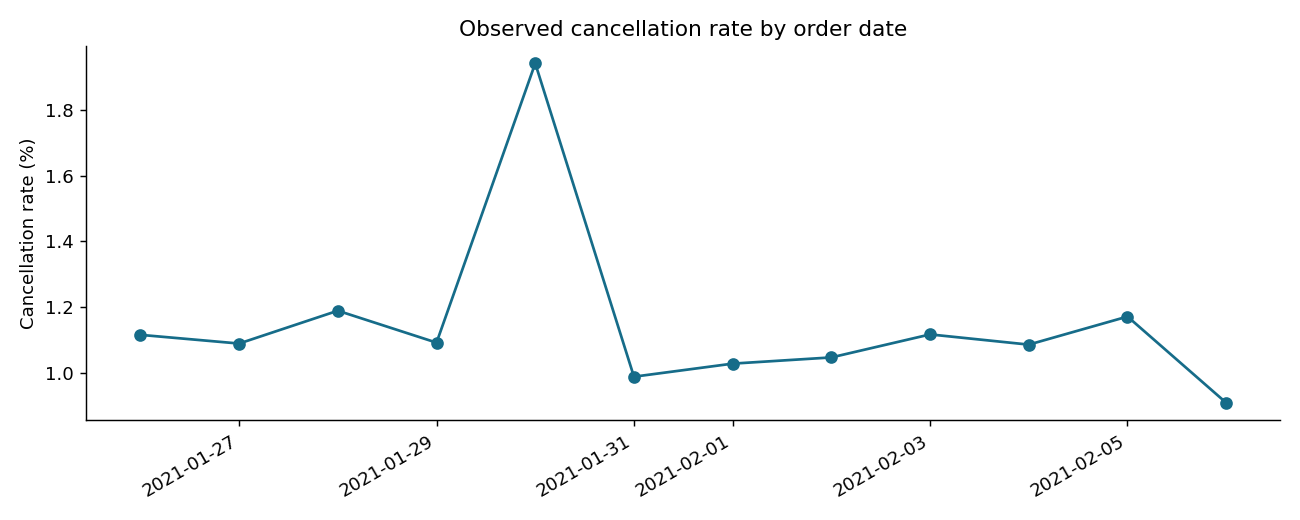

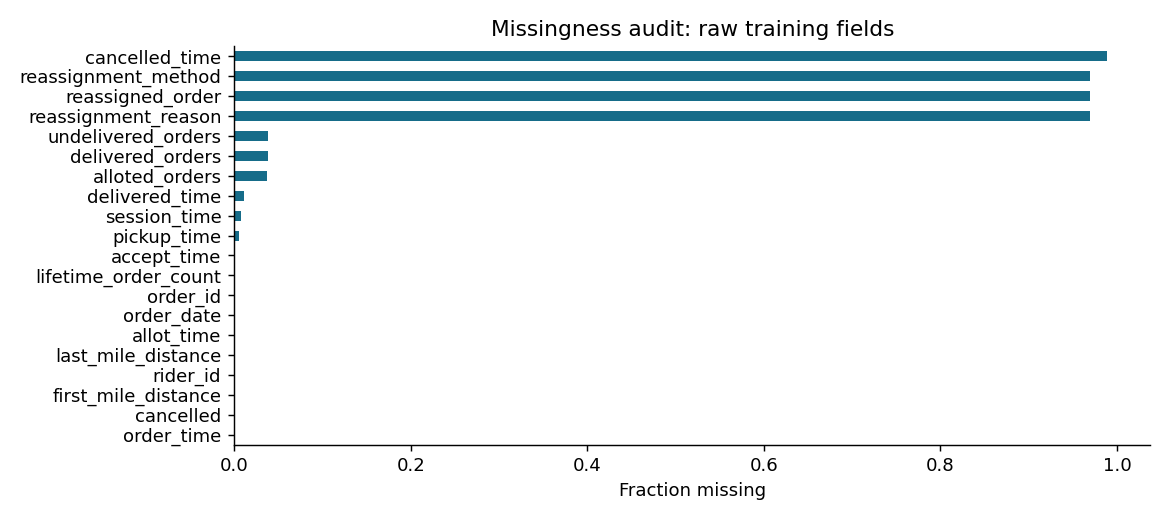

In [4]:
daily = pd.read_csv(ROOT / "reports/daily_cancellation_rates.csv")
display(daily)
display(Image(filename=str(ROOT / "reports/figures/daily_cancellations.png")))
display(Image(filename=str(ROOT / "reports/figures/missingness.png")))

Allocation Delay


,Unnamed: 0,rows,cancellations,cancellation_rate,wilson_lower,wilson_upper
0,"(-0.001, 0.5]",278527,2565,0.009209,0.008861,0.009571
1,"(0.5, 1.0]",96065,1038,0.010805,0.010171,0.011479
2,"(1.0, 2.0]",39048,447,0.011447,0.010439,0.012552
3,"(2.0, 5.0]",16819,233,0.013853,0.012195,0.015734
4,"(5.0, 10.0]",5254,81,0.015417,0.012422,0.019120
5,"(10.0, 30.0]",12157,351,0.028872,0.026041,0.032001
6,"(30.0, inf]",2122,495,0.233270,0.215768,0.251737


First Mile Distance


,first_mile_distance,rows,cancellations,cancellation_rate,wilson_lower,wilson_upper
0,"(-0.001, 0.5]",105244,1166,0.011079,0.010464,0.011729
1,"(0.5, 1.0]",94377,1007,0.010670,0.010034,0.011346
2,"(1.0, 2.0]",157035,1773,0.011290,0.010780,0.011825
3,"(2.0, 3.0]",89689,1168,0.013023,0.012301,0.013786
4,"(3.0, 5.0]",3429,88,0.025663,0.020878,0.031511
5,"(5.0, inf]",218,8,0.036697,0.018710,0.070730


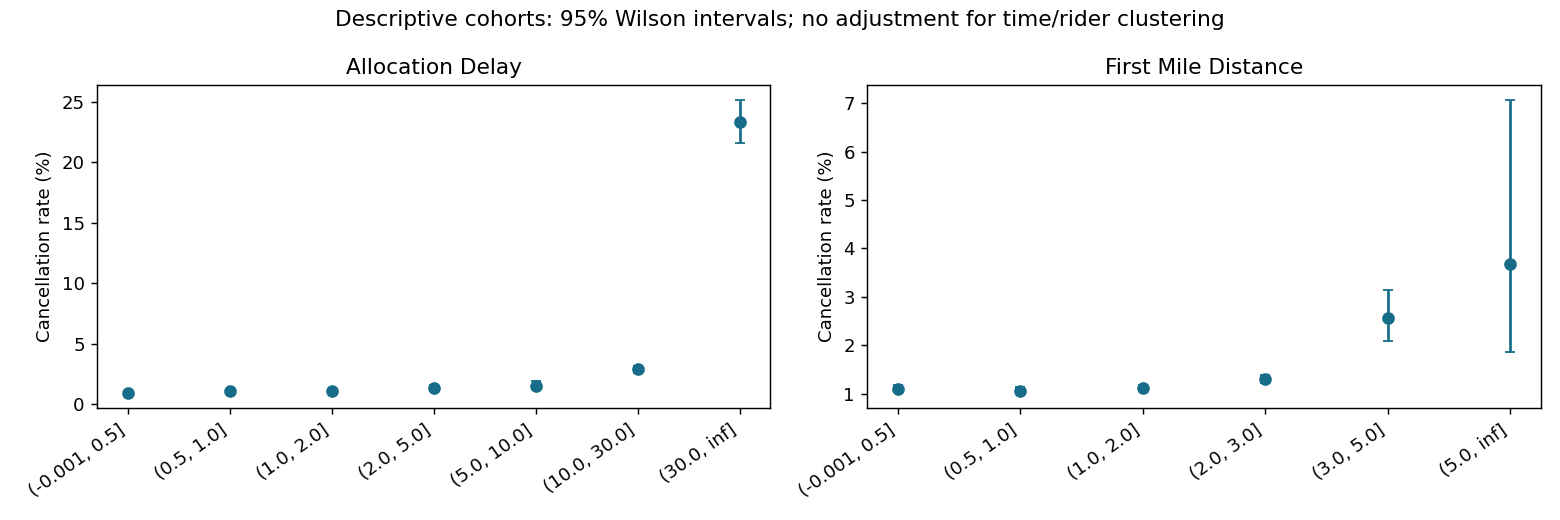

In [5]:
for name in ["allocation_delay", "first_mile_distance"]:
    print(name.replace("_", " ").title())
    display(pd.read_csv(ROOT / f"reports/cohort_{name}.csv"))
display(Image(filename=str(ROOT / "reports/figures/cohort_rates.png")))

Wilson intervals treat individual outcomes as independent. Repeated riders and
time dependence can make that approximation optimistic; these are descriptive
cohorts rather than adjusted treatment effects. Long allocation delay may reflect
operational difficulty or recording semantics. Investigate the event contract before acting.

## 3. Establish a prediction-time feature contract
We use an explicit allowlist: `order_time`, `allot_time`, `first_mile_distance`, and
`last_mile_distance`. Distance availability at allocation is an assumption to verify.
Check that `allot_time` is the intended allocation event, not a retrospective final reassignment.

Excluded from model input:
- Outcome timestamps: `pickup_time`, `delivered_time`, `cancelled_time`.
- Potentially later events: `accept_time` and reassignment fields.
- Undocumented snapshots: rider/session/order counts and session time.
- Order/rider IDs and redundant date fields.

Even a field present in the test CSV can leak information if it would be unavailable
at the real prediction time. See `DATA_DICTIONARY.md` for every field decision.

In [6]:
features = AllocationFeatures().fit_transform(train)
display(features.head())
display(features.describe().T)
# Outcome columns and IDs cannot enter the feature matrix.
assert not set(["cancelled", "order_id", "rider_id", "delivered_time", "cancelled_time"]) & set(features)
print("Feature allowlist confirmed:", len(features.columns), "engineered numeric features")

,first_mile_distance,last_mile_distance,total_distance,first_mile_share,allocation_delay_minutes,log_allocation_delay,allocation_hour_sin,allocation_hour_cos,allocation_weekday,is_weekend,order_hour
0,1.5666,2.65,4.2166,0.371532,0.400000,0.336472,0.577145,0.816642,1,0,2
1,2.5207,2.76,5.2807,0.477342,0.683333,0.520776,0.619094,0.785317,1,0,2
2,2.2074,4.80,7.0074,0.315010,0.133333,0.125163,0.639439,0.768842,1,0,2
3,2.1894,6.38,8.5694,0.255490,0.533333,0.427444,0.669131,0.743145,1,0,2
4,2.7870,4.01,6.7970,0.410034,0.850000,0.615186,0.728371,0.685183,1,0,3


,count,mean,std,min,25%,50%,75%,max
first_mile_distance,449992.0,1.229875,0.846180,0.000134,0.539500,1.138650,1.853000,42.038100
last_mile_distance,449992.0,2.968841,1.884091,0.000000,1.470000,2.670000,4.220000,22.410000
total_distance,449992.0,4.198715,2.163966,0.003224,2.517735,3.977800,5.601580,45.828100
first_mile_share,449992.0,0.315970,0.208141,0.000036,0.160954,0.289663,0.438948,1.000000
allocation_delay_minutes,449992.0,1.219751,4.582401,0.000000,0.016667,0.250000,0.800000,538.900000
log_allocation_delay,449992.0,0.422777,0.618210,0.000000,0.016529,0.223144,0.587787,6.291384
allocation_hour_sin,449992.0,-0.270789,0.734472,-1.000000,-0.882948,-0.598325,0.646124,1.000000
allocation_hour_cos,449992.0,-0.557059,0.277327,-1.000000,-0.790690,-0.587785,-0.337917,0.981627
allocation_weekday,449992.0,2.885234,1.742042,0.000000,1.000000,3.000000,4.000000,6.000000
is_weekend,449992.0,0.197166,0.397859,0.000000,0.000000,0.000000,0.000000,1.000000


Feature allowlist confirmed: 11 engineered numeric features


## 4. Simulate future deployment with chronological validation
Entire allocation dates partition the data. The earliest 60% of dates form training,
the next 20% validation, and the remaining dates holdout. Dates, not exact row counts,
determine the split. Outcome timestamps purge labels not yet resolved at the next boundary.

Validation selects the model and threshold. The holdout is evaluated only after
those choices are frozen. A later final refit is saved separately for test scoring.

In [7]:
fit_rows, validation_rows, holdout_rows, split = chronological_split(train)
display(pd.DataFrame({k: split[k] for k in ["train", "validation", "holdout"]}).T)
print("Training labels purged:", split["train_labels_purged"])
print("Validation labels purged:", split["validation_labels_purged"])
assert pd.to_datetime(fit_rows.allot_time).max() < pd.to_datetime(validation_rows.allot_time).min()
assert pd.to_datetime(validation_rows.allot_time).max() < pd.to_datetime(holdout_rows.allot_time).min()

,rows,cancellations,cancellation_rate,allocation_min,allocation_max
train,273735,3286,0.012004,2021-01-26 02:21:59,2021-02-01 19:51:21
validation,82307,887,0.010777,2021-02-02 02:24:45,2021-02-03 20:45:09
holdout,93903,1031,0.010979,2021-02-04 00:55:37,2021-02-06 10:52:57


Training labels purged: 34
Validation labels purged: 13


## 5. Compare baseline, linear, and nonlinear models
The experiment compares a prior-only baseline, unweighted logistic regression, and
histogram gradient boosting with 15 and 31 leaves. The linear pipeline learns median
imputation and scaling on training; boosting handles missing numeric values directly.
All candidates use the same feature and temporal contracts, random seed 42, and full
training rows. This is a bounded candidate comparison rather than exhaustive tuning.

Average precision is the primary selection metric. ROC AUC supplies a ranking view;
Brier score, log loss, and reliability plots diagnose probability quality. No separate
calibrator is fitted. Ranking metrics and a probability cutoff answer different questions.

,average_precision,roc_auc,brier_score,log_loss
logistic_regression,0.050863,0.592634,0.010456,0.057135
gradient_boosting_15_leaves,0.047101,0.600833,0.010443,0.057140
gradient_boosting_31_leaves,0.045524,0.598752,0.010453,0.057320
prior_baseline,0.010777,0.500000,0.010662,0.059607


Selected: logistic_regression


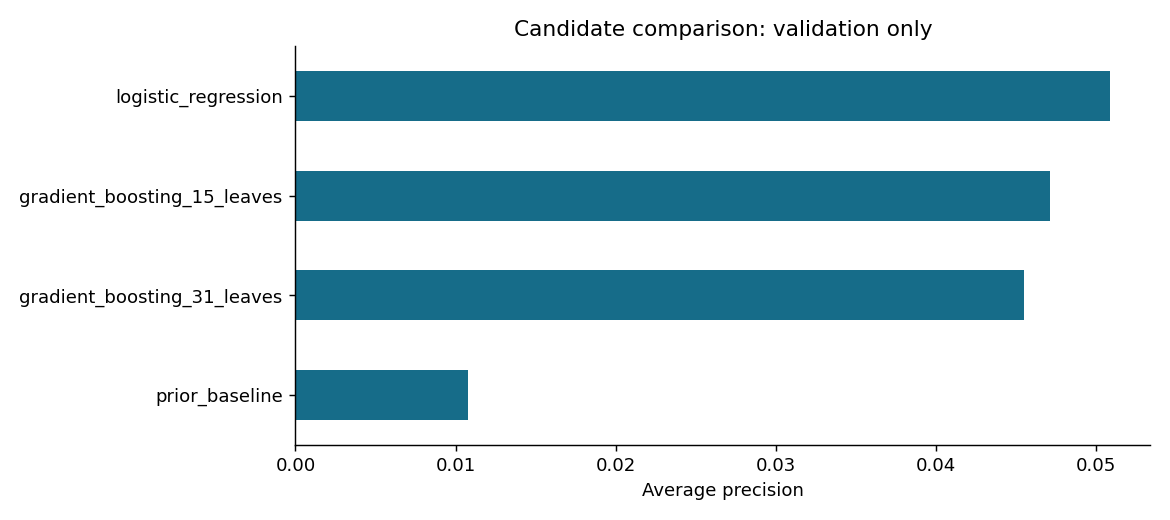

In [8]:
result = json.loads((ROOT / "reports/metrics.json").read_text())
comparison = pd.DataFrame(result["validation"]).T.sort_values("average_precision", ascending=False)
display(comparison[["average_precision", "roc_auc", "brier_score", "log_loss"]])
print("Selected:", result["selected_model"])
display(Image(filename=str(ROOT / "reports/figures/model_comparison.png")))

In [9]:
# Optional: reproduce all training artifacts. The completed run is already supplied.
RETRAIN = False
if RETRAIN:
    import subprocess
    subprocess.run([sys.executable, "-m", "rider_cancellation.train"], cwd=ROOT, check=True)
else:
    print("Reading the completed run. Set RETRAIN=True to run the CLI from this notebook.")

Reading the completed run. Set RETRAIN=True to run the CLI from this notebook.


## 6. Evaluate the frozen model on the later holdout
The class prevalence provides the no-skill average-precision reference. Queue metrics
ask how well a limited review budget ranks orders. Threshold metrics use a separate
validation-selected cutoff; the 5% queue is not the threshold's implied workload.

,selected_model,prior_baseline
average_precision,0.072195,0.010979
roc_auc,0.606639,0.500000
brier_score,0.010511,0.010860
log_loss,0.057271,0.060501
precision,0.229508,0.000000
recall,0.108632,0.000000
f1,0.147465,0.000000
alert_rate,0.005197,0.000000
threshold,0.059893,1.000000
precision_at_top_5_percent,0.041099,0.010009


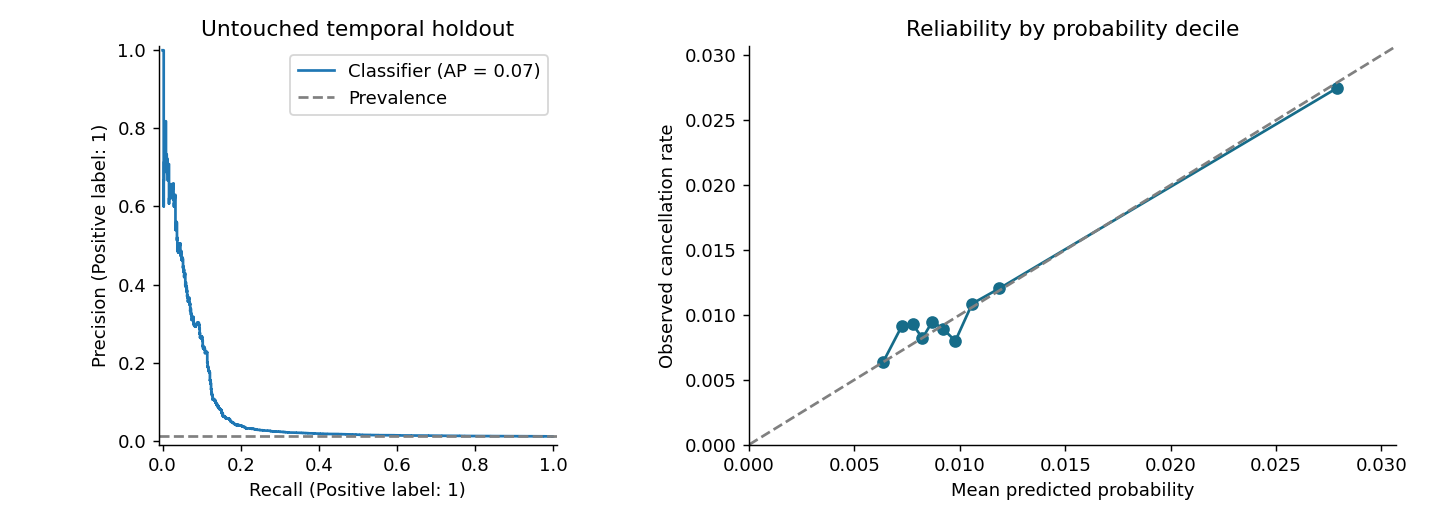

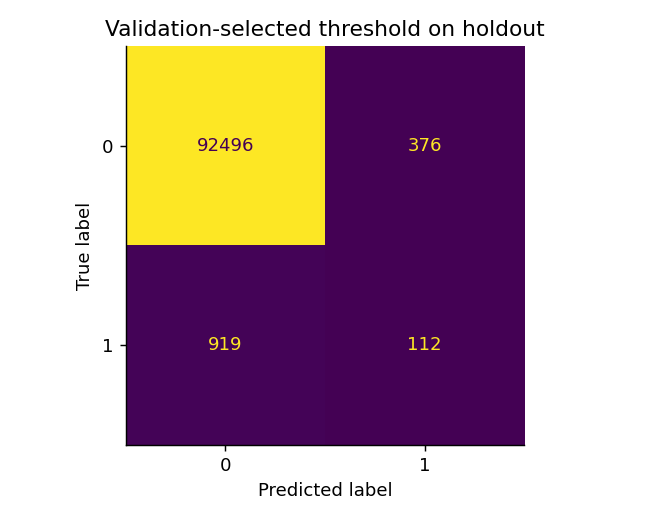

,allocation_date,rows,average_precision,roc_auc,brier_score,log_loss,precision,recall,f1,alert_rate,threshold,precision_at_top_5_percent,recall_at_top_5_percent,lift_at_top_5_percent,cancellation_rate,tn,fp,fn,tp
0,2021-02-04,39684,0.064128,0.606692,0.010429,0.056956,0.192308,0.104651,0.135542,0.005897,0.059893,0.037783,0.174419,3.486966,0.010836,39065,189,385,45
1,2021-02-05,42339,0.076800,0.614354,0.011162,0.060221,0.256545,0.099190,0.143066,0.004511,0.059893,0.045820,0.196356,3.927033,0.011668,41703,142,445,49
2,2021-02-06,11880,0.099951,0.606740,0.008468,0.047811,0.285714,0.168224,0.211765,0.005303,0.059893,0.040404,0.224299,4.485981,0.009007,11728,45,89,18


In [10]:
holdout = pd.Series(result["holdout"], name="selected_model")
baseline = pd.Series(result["holdout_baseline"], name="prior_baseline")
display(pd.concat([holdout, baseline], axis=1))
display(Image(filename=str(ROOT / "reports/figures/holdout_pr_calibration.png")))
display(Image(filename=str(ROOT / "reports/figures/confusion_matrix.png")))
display(pd.read_csv(ROOT / "reports/holdout_daily_metrics.csv"))

The result offers useful ranking signal but leaves most cancellations undetected.
This short holdout does not establish performance in other seasons, cities, or years.
Daily slice metrics reveal variation but do not provide a robust long-term confidence interval.

## 7. Make decision costs explicit
The default threshold minimizes validation classification cost under an illustrative
10:1 missed-cancellation-to-false-alert ratio. Alternative ratios are shown below.
These are scenarios, not measured business costs. Classification loss is not realized
savings: true-alert review costs, intervention success, and harms are not modeled.

In [11]:
sensitivity = pd.read_csv(ROOT / "reports/validation_cost_sensitivity.csv")
display(sensitivity[["false_negative_cost", "false_positive_cost", "threshold", "precision", "recall", "alert_rate", "validation_cost_per_1000"]])
print("Chosen costs:", result["illustrative_costs"])
print("Validation threshold:", result["threshold"])

,false_negative_cost,false_positive_cost,threshold,precision,recall,alert_rate,validation_cost_per_1000
0,1,1,0.716226,0.666667,0.002255,0.000036,10.764577
1,5,1,0.099431,0.290640,0.066516,0.002466,52.049036
2,10,1,0.059893,0.211382,0.087937,0.004483,101.826090
3,25,1,0.040515,0.125165,0.107103,0.009222,248.630129
4,50,1,0.019322,0.046009,0.170237,0.039875,485.147071


Chosen costs: {'false_negative': 10.0, 'false_positive': 1.0}
Validation threshold: 0.05989299616158877


## 8. Interpret signals and inspect distribution changes
Permutation importance uses a fixed validation sample of up to 15,000 orders with
three repeats. It measures predictive association, not causality. Correlated distance
and delay features can divide or mask importance. Error bars describe permutation
variation on that sample, not population uncertainty.

PSI uses training-derived quantile bins. Weekday drift can be large merely because
the short test period contains different weekdays. PSI is a descriptive check, not
a statistical test or a universal deployment gate.

,feature,mean_ap_decrease,std_ap_decrease
4,allocation_delay_minutes,0.026973,0.000868
1,last_mile_distance,0.003841,0.000955
2,total_distance,0.002121,0.000682
5,log_allocation_delay,0.001705,0.000933
3,first_mile_share,0.000583,0.000461
10,order_hour,0.000061,0.000175
9,is_weekend,0.000000,0.000000
6,allocation_hour_sin,-0.000084,0.000083
8,allocation_weekday,-0.000094,0.000168
7,allocation_hour_cos,-0.000124,0.000052


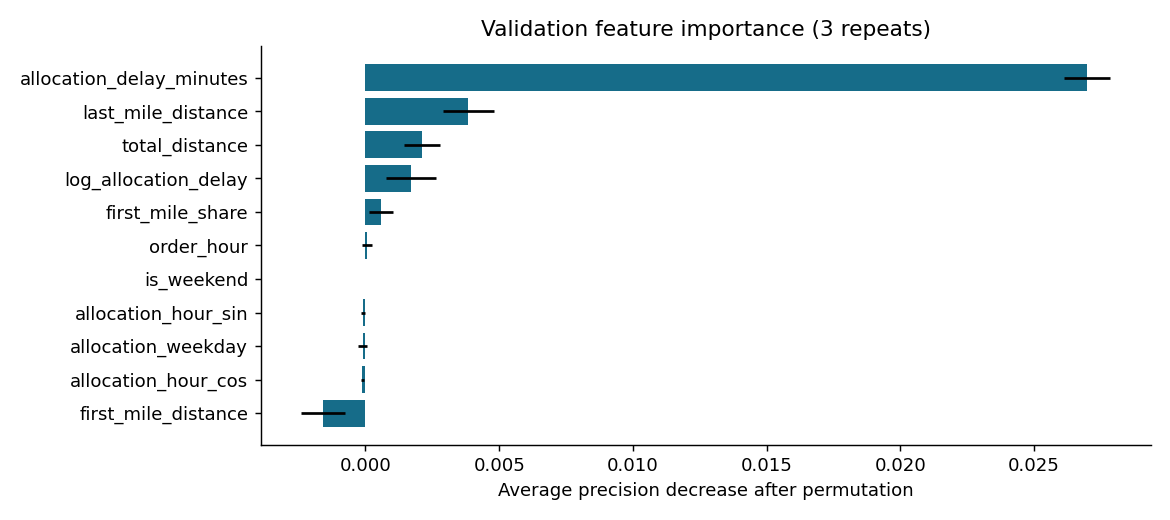

,feature,psi,reference_missing,current_missing
0,allocation_weekday,4.981676,0.0,0.0
1,allocation_delay_minutes,0.193999,0.0,0.0
2,log_allocation_delay,0.193999,0.0,0.0
3,first_mile_share,0.019088,0.0,0.0
4,allocation_hour_sin,0.017574,0.0,0.0
5,order_hour,0.013765,0.0,0.0
6,first_mile_distance,0.013131,0.0,0.0
7,allocation_hour_cos,0.011941,0.0,0.0
8,last_mile_distance,0.006478,0.0,0.0
9,total_distance,0.001495,0.0,0.0


In [12]:
display(pd.read_csv(ROOT / "reports/feature_importance.csv").sort_values("mean_ap_decrease", ascending=False))
display(Image(filename=str(ROOT / "reports/figures/feature_importance.png")))
display(pd.read_csv(ROOT / "reports/test_feature_drift.csv"))

## 9. Load the final pipeline and score orders
The final refit uses all labels resolved before the earliest test allocation and
retains the validation threshold. Its performance is not independently evaluated;
the reported holdout belongs to `evaluation_model.joblib`. Only load trusted joblib files.

The supplied submission template has binary decisions. We provide those and a separate
probability file because the actual external scoring rule was not supplied.

In [13]:
bundle = joblib.load(ROOT / "models/model.joblib")
example = pd.read_csv(ROOT / "examples/order.csv")
display(example)
display(predict_frame(bundle, example))
scored = pd.read_csv(ROOT / "predictions/test_probabilities.csv")
submission = pd.read_csv(ROOT / "predictions/submission.csv")
assert len(scored) == len(test_raw) == len(submission)
assert submission.order_id.equals(template.order_id)
assert submission.cancelled.isin([0, 1]).all()
assert scored.cancellation_probability.between(0, 1).all()
display(scored.head())
print(f"Validated {len(scored):,} test predictions in template order.")

,order_id,order_time,allot_time,first_mile_distance,last_mile_distance
0,100000001,2021-02-10 10:00:00,2021-02-10 10:02:00,1.5,3.0


,order_id,cancellation_probability,cancelled
0,100000001,0.010282,0


,order_id,cancellation_probability,cancelled
0,130231,0.011381,0
1,130232,0.011816,0
2,130233,0.008843,0
3,130234,0.008828,0
4,130235,0.007851,0


Validated 144,844 test predictions in template order.


## 10. Conclusions and responsible next steps
1. There is a measurable predictive signal under the stated allocation-time assumptions.
2. Linear modeling won this candidate comparison; complexity alone did not help.
3. High class imbalance makes majority-class accuracy an inadequate success criterion.
4. Outcome and ambiguous snapshot fields must stay excluded until their timing is established.
5. Ranking quality does not establish that operational intervention prevents cancellation.

Before real use, verify event semantics and data permissions; collect a longer window;
run rolling temporal and rider-cohort evaluations; recalibrate on a distinct recent
window; agree on workload and costs; and prospectively measure intervention effects.
Monitor input validity, score drift, queue size, delayed-label AP, precision/recall,
calibration, and operational outcomes. Do not use this score alone for rider penalties.

See `reports/findings.md`, `MODEL_CARD.md`, `DATA_DICTIONARY.md`, and the seven
contract tests for the complete supporting material.

In [14]:
manifest = json.loads((ROOT / "reports/run_manifest.json").read_text())
display(pd.Series(manifest["versions"], name="runtime"))
display(pd.DataFrame(manifest["files"])[["file", "bytes", "sha256"]])

python          3.13.9
pandas           2.3.3
numpy            2.3.5
scikit_learn     1.7.2
joblib           1.5.2
matplotlib      3.10.6
Name: runtime, dtype: object

,file,bytes,sha256
0,train.csv,85001325,2b89e8894cc0cb955a3a5b4aae08bd3a2339121a12c9af...
1,test.csv,20929360,626865db7f9a6dbcca83445aa6771c2e5b878b504487a7...
2,sample_submission.csv,1337350,c995cbf5861786c28842c5ba5f7ea8b8eee3019301b51a...
